# `insananalitigi` — Türkçe İnsan Analitiği Kütüphanesi Kullanım Rehberi

Bu not defteri, Craig Starbuck'ın *The Fundamentals of People Analytics: With Applications in R* kitabına eşlik eden R **peopleanalytics** paketinin **Türkçeleştirilmiş Python sürümünün** (`insananalitigi`) kullanımını gösterir.

12 veri setinde **sütun adları ve kategorik değerler** (Evet/Hayır, departmanlar, unvanlar, medeni durum vb.) Türkçeye çevrilmiştir.

## Kurulum

```bash
pip install insananalitigi-0.1.0-py3-none-any.whl
```

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import insananalitigi as ia

print("Sürüm:", ia.__version__)

Sürüm: 0.1.0


## 1. Mevcut veri setlerini listeleme

In [2]:
ia.veri_setleri()

['anket_yanitlari',
 'bordro',
 'calisanlar',
 'demografi',
 'devir_egilimleri',
 'durum',
 'is_bilgileri',
 'kidem',
 'onceki_istihdam',
 'performans',
 'tutum',
 'yan_haklar']

## 2. Veri seti yükleme

İki eşdeğer yol vardır:

- `ia.yukle("calisanlar")`
- `ia.calisanlar()` — her veri seti için kısayol fonksiyonu

In [3]:
calisanlar = ia.yukle("calisanlar")
calisanlar.shape

(1470, 36)

In [4]:
calisanlar[["calisan_id", "aktif", "cinsiyet", "departman",
            "is_unvani", "fazla_mesai", "aylik_ucret"]].head()

,calisan_id,aktif,cinsiyet,departman,is_unvani,fazla_mesai,aylik_ucret
0,1001,Hayır,Kadın,Satış,Satış Yöneticisi,Evet,16293
1,1002,Evet,Erkek,Araştırma ve Geliştirme,Araştırma Bilimcisi,Hayır,10573
2,1003,Hayır,Erkek,Araştırma ve Geliştirme,Laboratuvar Teknisyeni,Evet,15947
3,1004,Evet,Kadın,Araştırma ve Geliştirme,Araştırma Bilimcisi,Evet,9707
4,1005,Evet,Erkek,Araştırma ve Geliştirme,Laboratuvar Teknisyeni,Hayır,6933


In [5]:
# Kısayol fonksiyonu ile:
anket = ia.anket_yanitlari()
anket.head()

,aidiyet,caba,kapsayicilik,baglilik_1,baglilik_2,baglilik_3,mutluluk,psikolojik_guvenlik,kalma_niyeti_1,kalma_niyeti_2,kalma_niyeti_3,liderlik
0,4,3,5,3,3,3,3,6,5,4,5,5
1,4,3,5,3,3,5,3,7,3,5,5,5
2,4,3,3,4,4,3,5,4,5,5,5,4
3,2,4,4,2,3,3,3,2,1,2,2,3
4,5,5,5,4,4,5,4,7,4,5,5,5


## 3. Veri seti dokümantasyonu (`acikla`)

Orijinal R yardım sayfalarının Türkçe karşılığı; her değişkenin anlamını buradan okuyabilirsiniz.

In [6]:
print(ia.acikla("tutum"))

tutum (sentiment)

Açıklama: Çalışan tutum/duygu ölçümlerine ilişkin kurgusal veri. 1470 gözlem, 6 değişken.

Değişkenler:
  calisan_id        Her çalışan için benzersiz kimlik
  ortam_tatmini     Çalışma ortamı tatmini (1 = Düşük ... 4 = Çok yüksek)
  baglilik          Bağlılık (1 = Düşük ... 4 = Çok yüksek)
  is_tatmini        İş tatmini (1 = Düşük ... 4 = Çok yüksek)
  iliski_tatmini    İlişki tatmini (1 = Düşük ... 4 = Çok yüksek)
  is_yasam_dengesi  İş-yaşam dengesi (1 = Düşük ... 4 = Çok yüksek)



In [7]:
print(ia.acikla("devir_egilimleri"))

devir_egilimleri (turnover_trends)

Açıklama: İş unvanı, düzey ve uzaktan çalışma durumuna göre aylık işgücü devir oranlarına
ilişkin kurgusal veri (5 yıl x 12 ay). 3000 gözlem, 6 değişken.

Değişkenler:
  yil          Yıl (1-5)
  ay           Ay (1-12)
  is_unvani    İş unvanı (İnsan Bilimcisi, İnsan Analisti, Veri Mühendisi,
               İş Zekası Geliştiricisi, İçgörü Danışmanı)
  duzey        İş düzeyi (1 = Alt kademe ... 5 = Üst kademe)
  uzaktan      Uzaktan çalışma (Evet / Hayır)
  devir_orani  Aylık devir oranı (%)



## 4. Tüm veri setlerine toplu bakış

In [8]:
for ad, df in ia.tumunu_yukle().items():
    print(f"{ad:<18} {df.shape[0]:>5} satır x {df.shape[1]:>2} sütun")

anket_yanitlari      400 satır x 12 sütun
bordro              1470 satır x  6 sütun
calisanlar          1470 satır x 36 sütun
demografi           1470 satır x  7 sütun
devir_egilimleri    3000 satır x  6 sütun
durum               1470 satır x  2 sütun
is_bilgileri        1470 satır x  6 sütun
kidem               1470 satır x  6 sütun
onceki_istihdam     1470 satır x  2 sütun
performans          1470 satır x  3 sütun
tutum               1470 satır x  6 sütun
yan_haklar          1471 satır x  3 sütun


## 5. Örnek analiz 1 — İşten ayrılma oranı

`durum` tablosundaki `aktif` sütunu çalışanın hâlâ aktif olup olmadığını gösterir. `Hayır` = işten ayrılmış.

In [9]:
durum = ia.durum()
ayrilma_orani = (durum["aktif"] == "Hayır").mean()
print(f"Genel işten ayrılma oranı: %{ayrilma_orani*100:.1f}")

Genel işten ayrılma oranı: %16.1


### Departman ve fazla mesaiye göre ayrılma oranı

In [10]:
calisanlar["ayrilma"] = (calisanlar["aktif"] == "Hayır").astype(int)

ozet = calisanlar.pivot_table(index="departman", columns="fazla_mesai",
                              values="ayrilma", aggfunc="mean") * 100
ozet.round(1)

fazla_mesai,Evet,Hayır
departman,,
Araştırma ve Geliştirme,27.3,8.6
Satış,37.5,13.8
İnsan Kaynakları,29.4,15.2


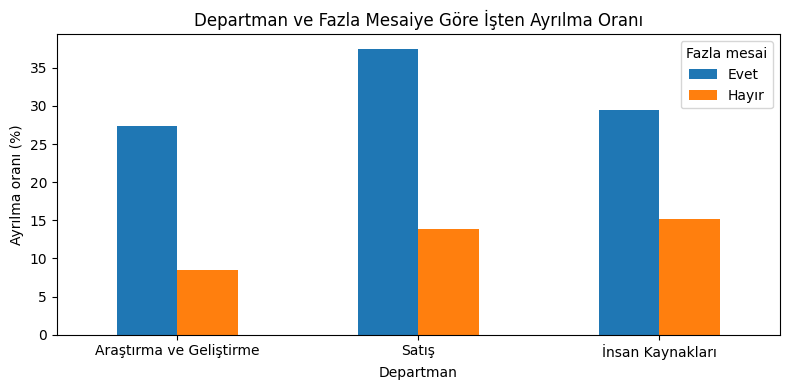

In [11]:
ax = ozet.plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_ylabel("Ayrılma oranı (%)")
ax.set_xlabel("Departman")
ax.set_title("Departman ve Fazla Mesaiye Göre İşten Ayrılma Oranı")
ax.legend(title="Fazla mesai")
plt.tight_layout()
plt.show()

## 6. Örnek analiz 2 — Tabloları birleştirme: iş tatmini ve ayrılma

Tablolar (`anket_yanitlari` ve `devir_egilimleri` hariç) `calisan_id` anahtarıyla birleştirilebilir.

In [12]:
birlesik = ia.tutum().merge(ia.durum(), on="calisan_id")
birlesik["ayrilma"] = (birlesik["aktif"] == "Hayır").astype(int)

tatmin_ayrilma = birlesik.groupby("is_tatmini")["ayrilma"].mean() * 100
tatmin_ayrilma.round(1)

is_tatmini
1    22.8
2    16.4
3    16.5
4    11.3
Name: ayrilma, dtype: float64

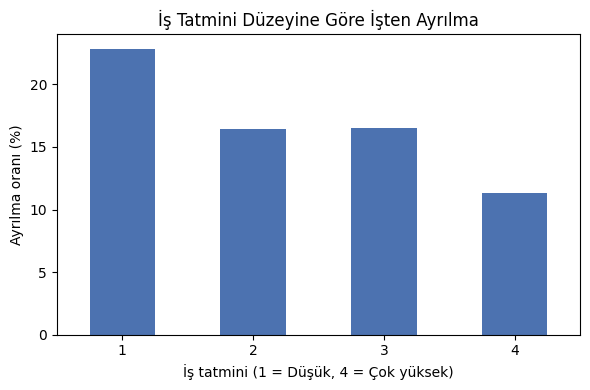

In [13]:
ax = tatmin_ayrilma.plot(kind="bar", figsize=(6, 4), rot=0, color="#4C72B0")
ax.set_xlabel("İş tatmini (1 = Düşük, 4 = Çok yüksek)")
ax.set_ylabel("Ayrılma oranı (%)")
ax.set_title("İş Tatmini Düzeyine Göre İşten Ayrılma")
plt.tight_layout()
plt.show()

## 7. Örnek analiz 3 — Lojistik regresyon ile ayrılma modeli

Kitaptaki R örneklerinin tipik karşılığı: `statsmodels` ile lojistik regresyon.

In [14]:
import statsmodels.formula.api as smf

model_df = calisanlar[["ayrilma", "yas", "aylik_ucret", "kurum_kidemi",
                       "is_tatmini", "is_yasam_dengesi", "fazla_mesai"]].copy()
model_df["fazla_mesai"] = (model_df["fazla_mesai"] == "Evet").astype(int)

model = smf.logit(
    "ayrilma ~ yas + aylik_ucret + kurum_kidemi + is_tatmini + is_yasam_dengesi + fazla_mesai",
    data=model_df
).fit(disp=0)
model.summary2().tables[1].round(4)

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,1.8478,0.5601,3.2992,0.0010,0.7501,2.9455
yas,-0.0488,0.0093,-5.2338,0.0000,-0.0671,-0.0306
aylik_ucret,-0.0000,0.0000,-0.3520,0.7249,-0.0001,0.0000
kurum_kidemi,-0.0496,0.0165,-3.0138,0.0026,-0.0819,-0.0173
is_tatmini,-0.3066,0.0678,-4.5188,0.0000,-0.4395,-0.1736
is_yasam_dengesi,-0.6155,0.1908,-3.2250,0.0013,-0.9895,-0.2414
fazla_mesai,1.4763,0.1551,9.5207,0.0000,1.1724,1.7802


In [15]:
import numpy as np
print("Odds oranları:")
print(np.exp(model.params).round(3))

Odds oranları:
Intercept           6.346
yas                 0.952
aylik_ucret         1.000
kurum_kidemi        0.952
is_tatmini          0.736
is_yasam_dengesi    0.540
fazla_mesai         4.377
dtype: float64


## 8. Örnek analiz 4 — Anket verisi (`anket_yanitlari`)

400 anonim çalışanın Likert ölçekli yanıtları. Üç maddelik bağlılık ölçeğinin iç tutarlılığı (Cronbach alfa) ve madde korelasyonları:

In [16]:
baglilik = anket[["baglilik_1", "baglilik_2", "baglilik_3"]]

def cronbach_alfa(df):
    k = df.shape[1]
    madde_var = df.var(axis=0, ddof=1).sum()
    toplam_var = df.sum(axis=1).var(ddof=1)
    return k / (k - 1) * (1 - madde_var / toplam_var)

print(f"Bağlılık ölçeği Cronbach alfa: {cronbach_alfa(baglilik):.3f}")

Bağlılık ölçeği Cronbach alfa: 0.883


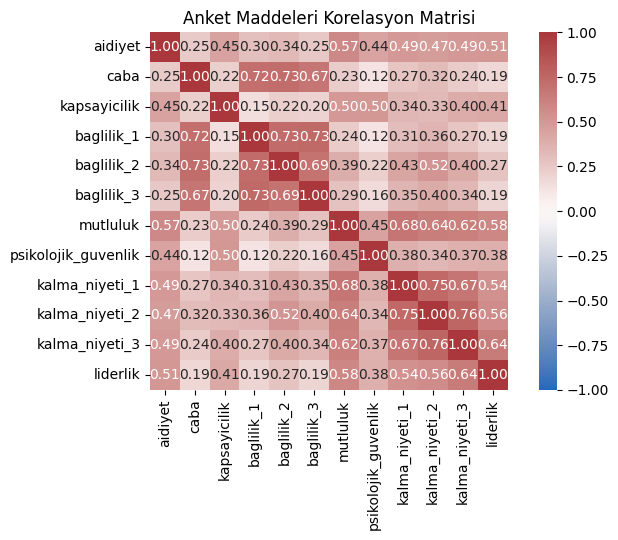

In [17]:
plt.figure(figsize=(7.5, 5.5))
sns.heatmap(anket.corr(), annot=True, fmt=".2f", cmap="vlag",
            vmin=-1, vmax=1, square=True)
plt.title("Anket Maddeleri Korelasyon Matrisi")
plt.tight_layout()
plt.show()

## 9. Örnek analiz 5 — Zaman serisi: `devir_egilimleri`

İş unvanı, düzey ve uzaktan çalışma durumuna göre aylık devir oranları (5 yıl × 12 ay).

In [18]:
devir = ia.devir_egilimleri()
devir.head()

,yil,ay,is_unvani,duzey,uzaktan,devir_orani
0,1,1,İnsan Bilimcisi,1,Evet,2.93
1,2,1,İnsan Bilimcisi,1,Evet,3.24
2,3,1,İnsan Bilimcisi,1,Evet,2.47
3,4,1,İnsan Bilimcisi,1,Evet,2.81
4,5,1,İnsan Bilimcisi,1,Evet,6.42


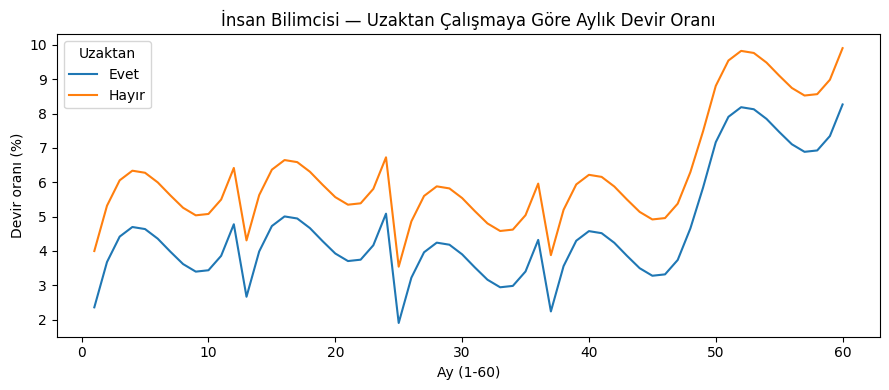

In [19]:
ib = devir[devir["is_unvani"] == "İnsan Bilimcisi"]
seri = (ib.assign(t=(ib["yil"] - 1) * 12 + ib["ay"])
          .pivot_table(index="t", columns="uzaktan", values="devir_orani", aggfunc="mean"))

ax = seri.plot(figsize=(9, 4))
ax.set_xlabel("Ay (1-60)")
ax.set_ylabel("Devir oranı (%)")
ax.set_title("İnsan Bilimcisi — Uzaktan Çalışmaya Göre Aylık Devir Oranı")
ax.legend(title="Uzaktan")
plt.tight_layout()
plt.show()

## Özet

| Fonksiyon | Açıklama |
|---|---|
| `ia.veri_setleri()` | 12 veri setinin adları |
| `ia.yukle(ad)` | Veri setini `DataFrame` olarak yükler |
| `ia.<veri_seti>()` | Kısayol: `ia.calisanlar()`, `ia.durum()`, ... |
| `ia.acikla(ad)` | Türkçe değişken açıklamaları |
| `ia.tumunu_yukle()` | Tüm setleri `{ad: DataFrame}` sözlüğü olarak yükler |

Türkçe CSV dosyaları pakete gömülüdür; ayrıca bağımsız CSV'ler halinde de teslim edilmiştir. Kitaptaki R örneklerini `pandas` + `statsmodels` ile birebir taşıyabilirsiniz.